In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

## Load and plot data

In [2]:
# Load real GDP (quarterly)
gdp_df = pd.read_csv('data/GDPC1.csv', index_col='observation_date', parse_dates=True)

# Load term spread (monthly) and collapse to quarterly averages
spread_monthly_df = pd.read_csv('data/T10Y3MM.csv', index_col='observation_date', parse_dates=True)
spread_df = spread_monthly_df.resample('QS').mean()
spread_df.columns = ['spread']

# Compute annualized real GDP growth rate
gdp_df['growth'] = 400 * np.log(gdp_df['GDPC1'] / gdp_df['GDPC1'].shift(1))

# Merge on common dates, restrict to pre-2020
df = gdp_df[['growth']].join(spread_df, how='inner').dropna()
df = df.loc[:'2019']

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


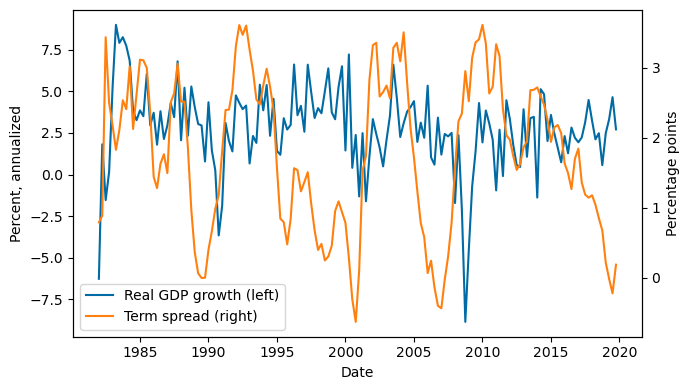

In [3]:
fig, ax1 = plt.subplots(figsize=(7, 4))

ax1.plot(df.index, df['growth'], label='Real GDP growth (left)', color='C0')
ax1.set_ylabel('Percent, annualized')
ax1.set_xlabel('Date')

ax2 = ax1.twinx()
ax2.plot(df.index, df['spread'], label='Term spread (right)', color='C1')
ax2.set_ylabel('Percentage points')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower left')

plt.tight_layout()
fig.savefig('output/gdp_spread.eps')
plt.show()

## Cross-correlogram

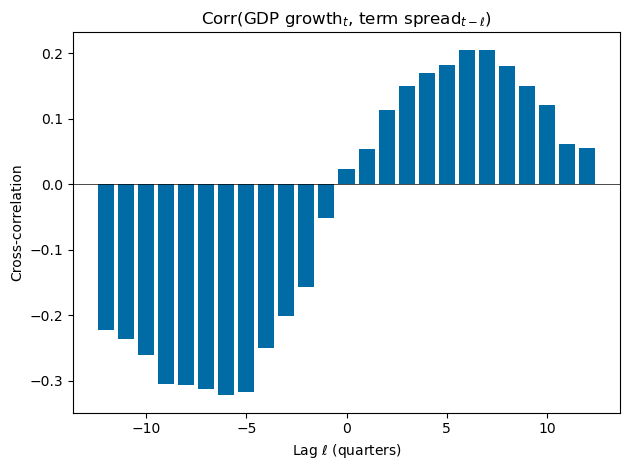

In [4]:
# Cross-correlogram between term spread and GDP growth
max_lag = 12
lags = np.arange(-max_lag, max_lag + 1)
T = len(df)
y = (df['growth'] - df['growth'].mean()).values
x = (df['spread'] - df['spread'].mean()).values
cgram = np.array([np.dot(y[max(h,0):T+min(h,0)], x[max(-h,0):T-max(h,0)]) / T
                for h in lags])
cgram /= np.std(df['spread']) * np.std(df['growth'])

fig, ax = plt.subplots()
ax.bar(lags, cgram, color='C0')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_xlabel('Lag $\\ell$ (quarters)')
ax.set_ylabel('Cross-correlation')
ax.set_title('Corr(GDP growth$_t$, term spread$_{t-\\ell}$)')
plt.tight_layout()
fig.savefig('output/correlogram.eps')
plt.show()

## Distributed lag regression

In [5]:
n_lags = 2

# Generate lagged variables
reg_df = df[['growth', 'spread']].copy()
for l in range(1, n_lags + 1):
    reg_df[f'growth_lag{l}'] = reg_df['growth'].shift(l)
    reg_df[f'spread_lag{l}'] = reg_df['spread'].shift(l)

# OLS estimation
y = reg_df['growth']
X_cols = [f'growth_lag{l}' for l in range(1, n_lags + 1)] + \
    [f'spread_lag{l}' for l in range(1, n_lags + 1)]

X = sm.add_constant(reg_df[X_cols])

model = sm.OLS(y, X, missing='drop').fit(cov_type='HC1')
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 growth   R-squared:                       0.260
Model:                            OLS   Adj. R-squared:                  0.239
Method:                 Least Squares   F-statistic:                     11.49
Date:                Wed, 03 Jun 2026   Prob (F-statistic):           3.94e-08
Time:                        14:00:09   Log-Likelihood:                -322.65
No. Observations:                 150   AIC:                             655.3
Df Residuals:                     145   BIC:                             670.4
Df Model:                           4                                         
Covariance Type:                  HC1                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.9231      0.409      2.259      

In [6]:
# Granger causality test
spread_lags = [f'spread_lag{l}' for l in range(1, n_lags + 1)]
restriction = ' = '.join(spread_lags) + ' = 0'
f_test = model.f_test(restriction)
print(restriction)
print(f_test)

spread_lag1 = spread_lag2 = 0
<F test: F=1.2094836277525283, p=0.30134309292175676, df_denom=145, df_num=2>


## VAR(1) simulation

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


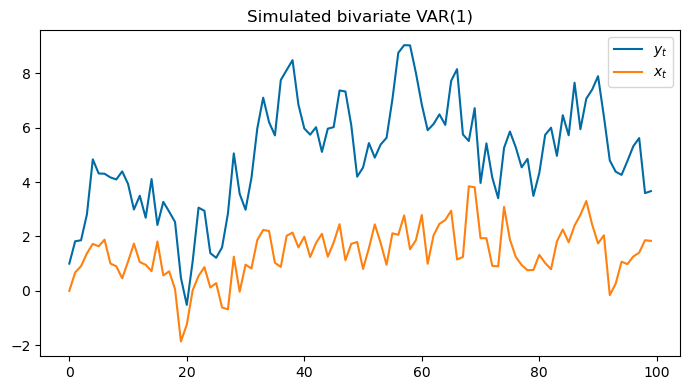

In [7]:
# VAR(1) parameters
c = np.array([1.0, 0.0])
A = np.array([[0.8, 0.1],
              [0.2, 0.3]])
Sigma = np.array([[1.0, 0.3],
                  [0.3, 0.5]])

# Simulate
T = 100
rng = np.random.default_rng(seed=31150)
Y = np.zeros((T, 2))
Y[0] = c  # initialize at intercept
for t in range(1, T):
    u = rng.multivariate_normal(np.zeros(2), Sigma)
    Y[t] = c + A @ Y[t - 1] + u

# Plot
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Y[:, 0], label='$y_t$')
ax.plot(Y[:, 1], label='$x_t$')
ax.legend()
ax.set_title('Simulated bivariate VAR(1)')
plt.tight_layout()
fig.savefig('output/var_sim.eps')
plt.show()

## VAR estimation

In [8]:
# Lag selection
var_model = sm.tsa.VAR(df[['growth', 'spread']])
lag_order = var_model.select_order(maxlags=12)
print(lag_order.summary())

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        1.850       1.892       6.362       1.867
1      -0.2777     -0.1517      0.7575     -0.2265
2     -0.5010*    -0.2909*     0.6060*    -0.4156*
3      -0.4799     -0.1857      0.6190     -0.3603
4      -0.4485    -0.07029      0.6388     -0.2948
5      -0.4239     0.03832      0.6549     -0.2361
6      -0.3939      0.1524      0.6751     -0.1719
7      -0.3414      0.2890      0.7120    -0.08523
8      -0.3104      0.4040      0.7350    -0.02005
9      -0.3407      0.4578      0.7137    -0.01623
10     -0.2924      0.5901      0.7499     0.06624
11     -0.3173      0.6493      0.7325     0.07549
12     -0.2991      0.7515      0.7472      0.1278
--------------------------------------------------


c:\Users\mikkelpm\AppData\Local\anaconda3\envs\ecma31150\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


In [9]:
# Estimate VAR with selected lag order
var_results = var_model.fit(ic='aic')
print(var_results.summary()) # warning: SE assume homoskedasticity

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Wed, 03, Jun, 2026
Time:                     14:00:09
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   0.140655
Nobs:                     150.000    HQIC:                 0.0214877
Log likelihood:          -411.178    FPE:                   0.941760
AIC:                   -0.0600540    Det(Omega_mle):        0.881982
--------------------------------------------------------------------
Results for equation growth
               coefficient       std. error           t-stat            prob
----------------------------------------------------------------------------
const             0.923150         0.408835            2.258           0.024
L1.growth         0.343830         0.079882            4.304           0.000
L1.spread        -0.258465         0.375531           -0.688           0.49